In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [7]:
train_df = pd.read_csv('train.csv')
test_df  = pd.read_csv('test.csv')

print(train_df)
print(test_df)

             medical_specialty  \
0     cardiovascular-pulmonary   
1     cardiovascular-pulmonary   
2     cardiovascular-pulmonary   
3     cardiovascular-pulmonary   
4     cardiovascular-pulmonary   
...                        ...   
2608                   surgery   
2609                   surgery   
2610                   surgery   
2611                   surgery   
2612                   surgery   

                                            description  \
0     chest pain possible syncopal spells she has be...   
1     the patient is 14 months old comes in with a c...   
2     fiberoptic bronchoscopy diagnostic hemoptysis ...   
3        left lower extremity venous doppler ultrasound   
4     the patient was admitted after undergoing a dr...   
...                                                 ...   
2608  thoracic right sided discectomy at t8 t9 the p...   
2609  acute acalculous cholecystitis open cholecyste...   
2610  arthrodesis anterior interbody technique anter...   
2

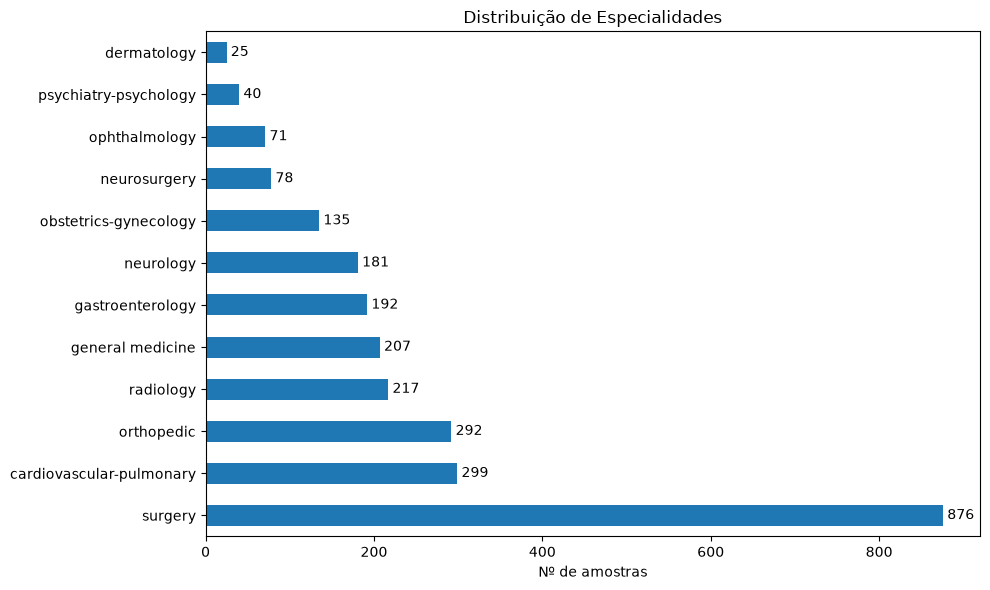

In [8]:
def summarize(df: pd.DataFrame):
    counts = df['medical_specialty'].value_counts()

    ax = counts.plot(kind='barh', figsize=(10, 6))
    ax.bar_label(ax.containers[0], padding=3)
    ax.set_xlabel("Nº de amostras")
    ax.set_ylabel("")
    plt.title("Distribuição de Especialidades")
    plt.tight_layout()
    plt.show()

summarize(train_df)


In [9]:
print(train_df['keywords'].isna().sum())
print(test_df['keywords'].isna().sum())

0
0


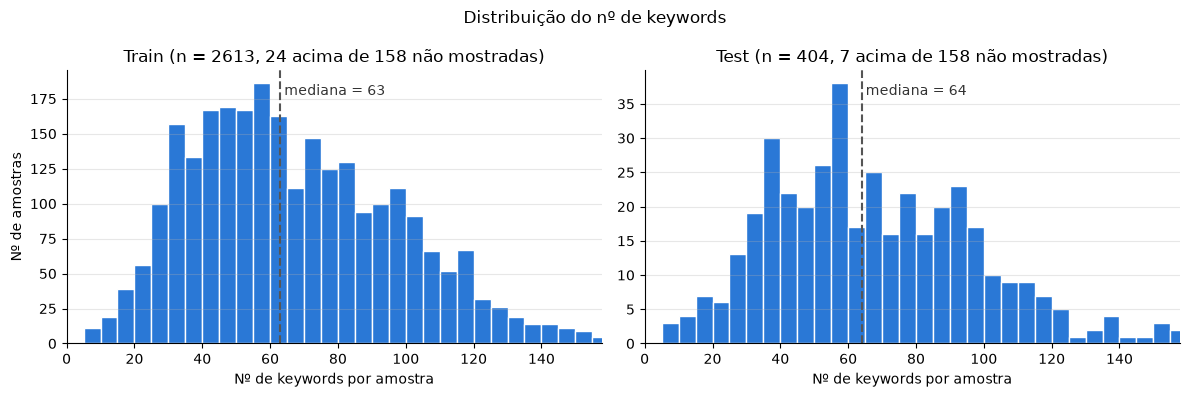

In [10]:
def plot_keywords_dist(dfs: dict[str, pd.DataFrame]):
    counts = {name: df['keywords'].str.split(',').str.len() for name, df in dfs.items()}

    upper = np.percentile(pd.concat(counts.values()), 99)    # corta outliers extremos
    bins  = np.arange(0, upper + 5, 5)

    fig, axes = plt.subplots(1, len(dfs), figsize=(12, 4))

    for ax, (name, n_keywords) in zip(np.atleast_1d(axes), counts.items()):
        n_out = (n_keywords > upper).sum()

        ax.hist(n_keywords, bins=bins, color='#2a78d6', edgecolor='white', linewidth=1)
        ax.axvline(n_keywords.median(), color='#555555', linestyle='--', linewidth=1.5)
        ax.text(n_keywords.median(), ax.get_ylim()[1] * 0.95, f' mediana = {n_keywords.median():.0f}', color='#333333', va='top')

        ax.set_xlim(0, upper)
        ax.set_title(f"{name} (n = {len(n_keywords)}, {n_out} acima de {upper:.0f} não mostradas)")
        ax.set_xlabel("Nº de keywords por amostra")
        ax.grid(axis='y', alpha=0.3)
        ax.spines[['top', 'right']].set_visible(False)

    np.atleast_1d(axes)[0].set_ylabel("Nº de amostras")
    fig.suptitle("Distribuição do nº de keywords")
    plt.tight_layout()
    plt.show()

plot_keywords_dist({'Train': train_df, 'Test': test_df})
